## A basket in one account

Five coins traded in one account from one table of weights, a row a day and a column a
coin: each held while it closes above its 100-day average, sized inversely to its
volatility, the five together the whole account at most. Daily bars of Binance's spot pairs,
2023 to 2025. The Result keeps each coin's own record beside the account's.

In [1]:
import pathlib

import exchange_router
import matplotlib.pyplot
import numpy
import pandas
import probatum

matplotlib.pyplot.style.use(style="../oceano.mplstyle")

print(f"probatum {probatum.__version__}, exchange-router {exchange_router.__version__}")

probatum 4.0.0, exchange-router 4.0.0


### The bars

One Data of five instruments on one clock, `(T, N)` in every field.

In [2]:
PATH = pathlib.Path("../bars/binance-spot-basket-1d-2023-2025")

if PATH.exists():
    basket = probatum.Data.load(path=PATH)
else:
    with exchange_router.Router.local(exchanges=["binance"]) as router:
        basket = probatum.Data.from_router(router, exchange="binance", market="spot",
                                           interval="1d",
                                           symbols=["BTCUSDT", "ETHUSDT", "SOLUSDT",
                                                    "BNBUSDT", "XRPUSDT"],
                                           start="2023-01-01", end="2025-12-31")
    basket.save(path=PATH)

print(basket, basket.names, basket.closes.shape)

Data(5 instruments, 1d, 1096 bars from 2023-01-01 00:00 to 2025-12-31 00:00) ('BTCUSDT', 'ETHUSDT', 'SOLUSDT', 'BNBUSDT', 'XRPUSDT') (1096, 5)


### Weights as a table

Every indicator takes a `(T, N)` array and runs each column over its own bars. A table of
weights is matched to the bars by its times and to the instruments by its column names;
`backtest` reads it as it reads an array. The last days anything was held:

In [3]:
closes  = basket.closes
returns = numpy.log(closes / probatum.ta.shift(closes))
spread  = probatum.ta.stdev(returns, length=30)
above   = closes > probatum.ta.sma(closes, length=100)

raw   = numpy.where(above, 1.0 / spread, 0.0)
total = raw.sum(axis=1, keepdims=True)

weights = pandas.DataFrame(numpy.divide(raw, total, out=numpy.zeros_like(raw),
                                        where=total > 0.0),
                           index=pandas.to_datetime(basket.time, utc=True),
                           columns=basket.names)

weights[weights.sum(axis="columns") > 0.0].iloc[-3:].round(decimals=3)

,BTCUSDT,ETHUSDT,SOLUSDT,BNBUSDT,XRPUSDT
2025-11-08 00:00:00+00:00,0.0,0.0,0.0,1.0,0.0
2025-11-09 00:00:00+00:00,0.0,0.0,0.0,1.0,0.0
2025-11-10 00:00:00+00:00,0.0,0.0,0.0,1.0,0.0


### The run

A rebalance under 2% of the account is left undone, so a weight is brought back only once
it has drifted.

In [4]:
book = probatum.backtest(weights, data=basket, venue="binance_spot", tolerance=0.02)

book

,run,buy_and_hold,low,high,level,method,why_none
total_return_pct,-9.60,483.46,-84.49,402.98,0.95,"studentized stationary block bootstrap, blocks of 2 bars",
cagr_pct,-3.31,80.03,-46.27,71.34,0.95,"studentized stationary block bootstrap, blocks of 2 bars",
volatility_pct,45.50,64.46,40.75,52.48,0.95,"studentized stationary block bootstrap, blocks of 2 bars",
sharpe,0.16,1.23,-1.10,1.41,0.95,"delta method, Newey-West lag 10",
max_drawdown_pct,57.02,49.95,33.72,87.09,0.95,"middle of resampled histories, stationary block bootstrap, blocks of 2 bars",
exposure_pct,75.43,,,,,,
num_trades,127,,,,,,
win_rate,0.19,,0.13,0.26,0.95,percentile bootstrap of round trips,
profit_factor,0.95,,0.41,1.90,0.95,BCa bootstrap of round trips,
costs,"2,106",,,,,,


### Each coin's part

`book[name]` is one instrument's record: its position, its weight of the account and what it
has made, at every bar, with its own fills and round trips. The coins' pnl add up to the
account's.

In [5]:
parts = pandas.DataFrame({name: {"pnl, USDT": book[name].pnl[-1],
                                 "round trips": len(book[name].trades),
                                 "fills": len(book[name].fills),
                                 "mean weight": book[name].weight.mean(),
                                 "days held": int((book[name].weight > 0.0).sum())}
                          for name in basket.names}).T

print(f"the coins' pnl {parts['pnl, USDT'].sum():,.2f}, "
      f"the account's {book.equity[-1] - book.equity[0]:,.2f}")

parts.astype({"round trips": int, "fills": int, "days held": int}).round(decimals=3)

the coins' pnl -960.02, the account's -960.02


,"pnl, USDT",round trips,fills,mean weight,days held
BTCUSDT,1608.699,24,222,0.212,663
ETHUSDT,-568.997,24,177,0.129,578
SOLUSDT,-1241.379,36,176,0.102,581
BNBUSDT,3913.551,16,190,0.177,591
XRPUSDT,-4671.898,27,176,0.131,520


### Each coin's pnl over the three years

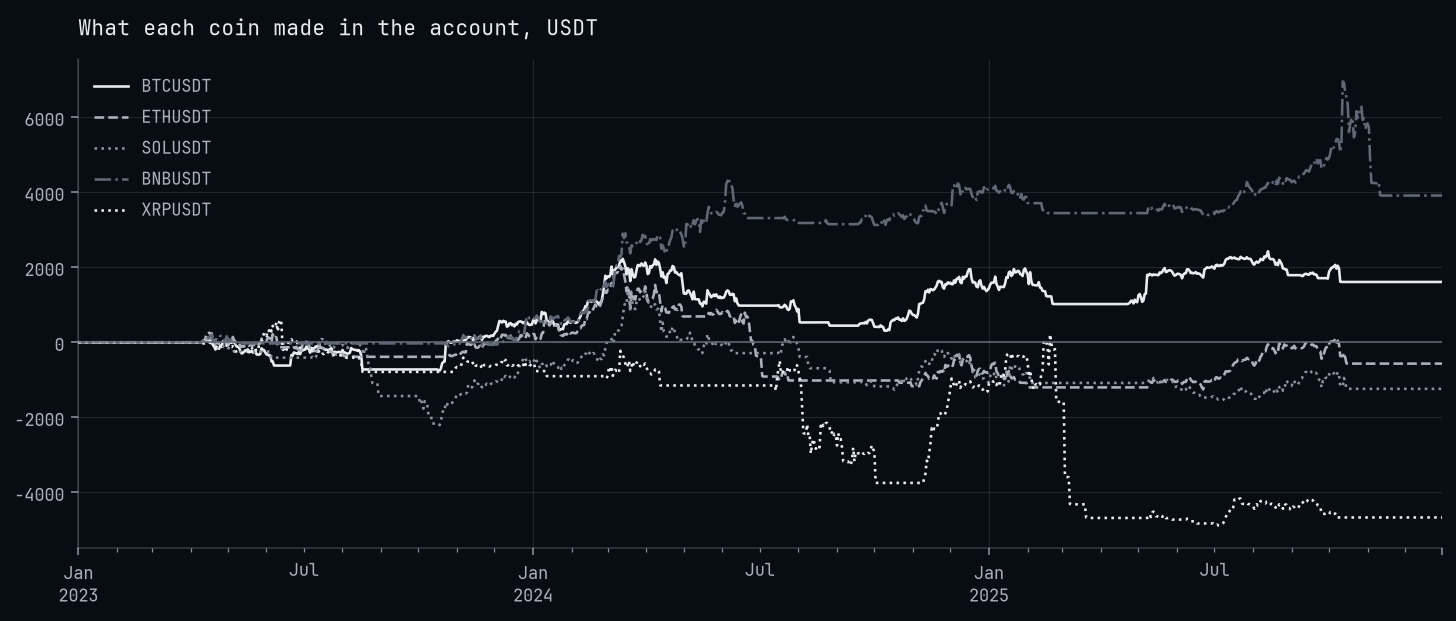

In [6]:
pnl = pandas.DataFrame({name: book[name].pnl for name in basket.names},
                       index=pandas.to_datetime(book.time, utc=True))

axes = pnl.plot(title="What each coin made in the account, USDT", xlabel="")
axes.axhline(y=0.0, color="C3", linewidth=0.8)
matplotlib.pyplot.show()

### The book one coin at a time

The candles of one instrument with its round trips, its weight on a panel of its own, and
the whole account's equity under them.

In [7]:
for name in ["SOLUSDT", "XRPUSDT"]:
    book.chart(probatum.chart.marks.Line(book[name].weight, name=f"{name}'s weight",
                                         panel="weight", step=True),
               instrument=name, focus=365, height=480,
               title=f"{name} of the five, daily").show()